# Python Internals: Stages of Execution (The Python Execution Model)

> *“One of my most productive days was throwing away 1,000 lines of code.”*
> — Ken Thompson

---

## Compiled vs Interpreted Languages – A Conversation

**Raj:**  
A compiled language is one where the code is first put through a compiler before it is able to be run.  
An example is the **C programming language**. To run C code, first you have to run a compiler like `gcc` or `clang`, and then finally you can run your code.  
A compiled language gets converted to **machine code**—the ones and zeroes that your CPU understands.

**Anjali:**  
But wait, isn’t **Java** a compiled language?

**Raj:**  
Yes, Java is a compiled language.

**Anjali:**  
But isn’t the output of the regular Java compiler a `.class` file? That’s **bytecode**, isn’t it?

**Raj:**  
That’s correct. Bytecode isn’t machine code, but Java is still a compiled language.  
This is because there are many problems that the **compiler can catch**, so you will need to correct errors **before your program starts running**.

**Anjali:**  
What about **interpreted languages**?

**Raj:**  
An interpreted language is one that relies on a separate program, aptly called an **interpreter**, to actually run your code.  
An interpreted language does not require the programmer to run a compiler first.  
Because of this, any errors that you make will be **caught while your program is running**.  
**Python** is an interpreted language—there is no separate compiler, and all errors that you make are caught at **runtime**.

**Anjali:**  
If Python is not a compiled language, then why does the standard library include modules called `py_compile` and `compileall`?

**Raj:**  
Well, those modules just convert Python to **bytecode**.  
They don’t convert Python to **machine code**, so Python is still considered an **interpreted language**.

**Anjali:**  
So, both Python and Java are converted to **bytecode**?

**Raj:**  
Correct.

**Anjali:**  
Then how is Python an interpreted language and yet Java is a compiled language instead?

**Raj:**  
Because all errors in Python are caught at **runtime**.


In [1]:
"""
1. Example for Demonstrating stages of compilation.
2. Let's learn by debugging
"""
# Step 1
1/0
print() = None
if False
    n="hello

SyntaxError: unterminated string literal (detected at line 9) (4285139062.py, line 9)

In [2]:
# Step 2
1 / 0
print() = None
if False
    n = "hello"

SyntaxError: cannot assign to function call here. Maybe you meant '==' instead of '='? (2586608014.py, line 3)

In [3]:
# Step 3
1 / 0
print()
if False
    n = "hello"

SyntaxError: expected ':' (2633337408.py, line 4)

In [4]:
# Step 4
1 / 0
print()
if False:
    n = "hello"

ZeroDivisionError: division by zero

In [5]:
# Step 5 => Success
1 / 0.1
print()
if False:
    n = "hello"

**What happens when you install Python ?**

- When you install Python on your system (e.g., using the official installer from python.org), a number of components are set up to create a complete Python development environment. Let's look into some important python modules which gets installed .
  
✅ 1. Python Interpreter (CPython)
    - The core component that parses, compiles, and executes your Python code.
    - It converts .py files into bytecode and runs them via the Python Virtual Machine (PVM).
    
✅ 2. Standard Library
    - A huge collection of modules (in-built packages) that provide: File I/O, Regular expressions (re), Networking (socket, http), Math (math, statistics) etc
    
✅ 3. Bytecode Compiler
    - .py files are automatically compiled to .pyc files and stored in the __pycache__ directory.
    - This helps speed up execution.



**Is Python Compiled or Interpreted?**
- Python is interpreted. Let's understand in details.
- The Python interpreter software you download from python.org is called CPython because it's written in C.
- When you run a Python program, the interpreter first compiles it to bytecode and then runs the bytecode. So you could say that Python is compiled.
- The CPython interpreter really is an interpreter. But it also is a compiler.
- Python must go through a few stages before ever running the first line of code: 1. Scanning and 2. Parsing

**NOTE** 
1. Interpreter	- General term for any system that executes code without compiling to native machine code first
1. CPython	- The full Python interpreter, written in C
2. PVM	- The runtime engine inside CPython that runs bytecode

---

- Sample Python code for Analysis : 
```python
   x = 5 + 3
```
    The above code is saved in .py file in local system.

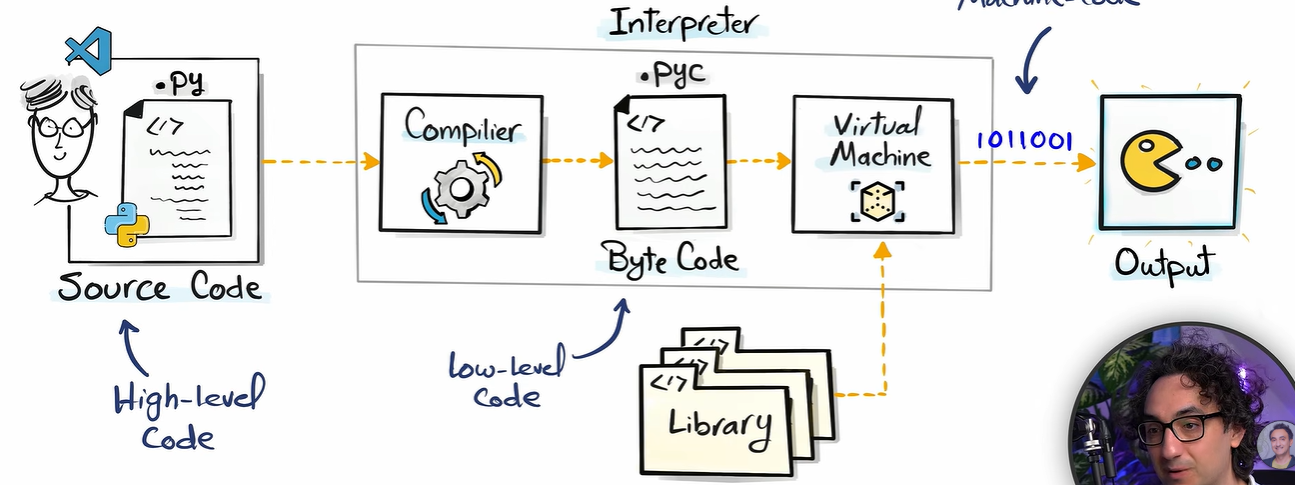


### 6.1. Lexical Analysis and Tokenization - Scanning Phase

- The first step in the execution process is **lexical analysis**, also known as **tokenization**.
- During this phase, the source code is converted into a sequence of **tokens**.
- **Tokens**:  
  `[ x (identifier) , = (operator), 5 (literal), + (operator), 3 (literal) ]`



### 6.2. Syntax Analysis and Abstract Syntax Tree (AST) - Parsing Phase

- During this phase, the sequence of tokens is analyzed to determine its grammatical structure.
- The output of this phase is an Abstract Syntax Tree (AST), which represents the hierarchical structure of the source code.
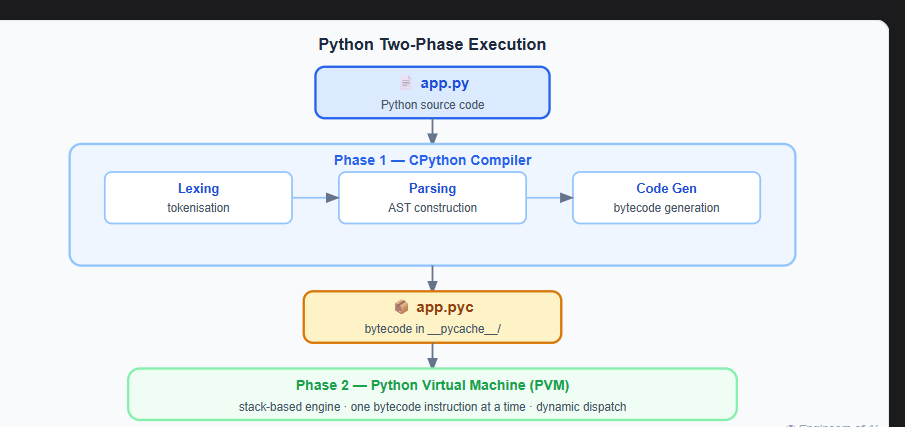


### 6.3. Bytecode Compilation

- The AST is then compiled into bytecode, which is a low-level, platform-independent representation of the source code.
- Bytecode is a set of instructions that can be efficiently executed by the Python Virtual Machine (PVM).
- Generates a .pyc file
- Bytecode Examples
  ```python
    1 LOAD_CONST 5
    2 LOAD_CONST 3
    3 BINARY_ADD
    4 STORE_NAME x
    ```


In [6]:
code_obj = compile('x = a+ b', '', 'exec')
print(type(code_obj))
# <class 'code'>

import dis
dis.dis(code_obj)

<class 'code'>
  0           RESUME                   0

  1           LOAD_NAME                0 (a)
              LOAD_NAME                1 (b)
              BINARY_OP                0 (+)
              STORE_NAME               2 (x)
              LOAD_CONST               0 (None)
              RETURN_VALUE




### 6.4. Execution by the Python Virtual Machine (PVM)

- PVM is the Python Interpreter that converts the Python byte code into machine-executable code.
- PVM interpreter reads and executes the given file line by line.
- CPU runs the native machine instructions triggered by the PVM
- It manages memory, automatically cleaning up unused objects using a garbage collector
- PVM also provides thread safety With a Global Interpreter Lock (GIL) that comes with Cpython.
  
---
